# Motor non-linearities from complex test signals
This notebook analyzes the three complex signals: chirp, triangle and PRBS. On top of that comes up with the model that solves identified nonlinearities: dead zone, Coulomb/Viscious friction and a backward/forward asymmetry.

| Signal | Program | File | Settings | Used for |
|---|---|---|---|---|
| Chirp | `motor_signal_chirp.qrs` | `chirp_signal_data.txt` | A = 80 %, 0.1 → 5 Hz over 30 s | dynamics; a check at high PWM |
| Triangle | `motor_signal_triangle.qrs` | `triangle_signal_data.txt` | A = 40 %, P = 32 s, 5 periods | identification: dead zone, steady-state curve, asymmetry, $T_m$ |
| PRBS | `motor_signal_prbs.qrs` | `prbs_signal_data.txt` (12 Nov), `prbs_signal_data_2.txt` (13 Nov) | ±20 %, 7-bit shift register, clock 0.5 s, 2 periods (127 s) | validation only, not used for fitting |

All three were run with the wheels lifted. Every file has the same six columns:

| column | meaning | unit |
|---|---|---|
| 0 | phase: 2 = the 3 s zero block (motors off), 3 = the signal | |
| 1 | motor power setpoint | % |
| 2 | left wheel encoder (E4) | deg |
| 3 | right wheel encoder (E3) | deg |
| 4 | time since the start of the signal | ms |
| 5 | battery voltage | V |

In [1]:
try:
    from google.colab import files    # file work module
    uploaded = files.upload()         # upload file context window
except ImportError:
    pass

Using `loadtxt` we read the six columns of each file and convert them to SI units. The programs send `int(v)` to the motors, so the applied PWM is `trunc` of the logged value. The battery voltage is taken as one value per run, its median.

In [2]:
import os                           # file paths
import numpy as np                  # array work module
import matplotlib.pyplot as plt     # data visualization
import pandas as pd                 # tables
from scipy import optimize          # data fitting

DATA = 'motor_data' if os.path.isdir('motor_data') else '.'          # data folder in the repo, or next to the notebook in Colab
os.makedirs('report_figs', exist_ok=True)
colors = {'L': '#2a6fdb', 'R': '#e0533d'}

def load(name, u_bat=None):
    data = np.loadtxt(os.path.join(DATA, name))                      # columns: phase, PWM, encL, encR, time_ms, battery
    data = data[data[:, 0] == 3]                                     # the signal (phase 2 = zero block)
    if u_bat is None:
        u_bat = np.median(data[:, 5])                                # battery voltage of the run, V
    pwm = np.trunc(data[:, 1])                                       # applied PWM, %
    return {'t':   data[:, 4] / 1000,                                # SI conversion, s
            'pwm': pwm,
            'U':   pwm / 100 * u_bat,                                # applied voltage, V
            'bat': u_bat,
            'L':   np.deg2rad(data[:, 2] - data[0, 2]),              # SI conversion, rad
            'R':   np.deg2rad(data[:, 3] - data[0, 3])}

tri = load('triangle_signal_data.txt')
chp = load('chirp_signal_data.txt')
prb = load('prbs_signal_data_2.txt')                                # 13 Nov re-run, battery logged
prb_12 = load('prbs_signal_data.txt', u_bat=tri['bat'])              # 12 Nov run: its battery column is 0, so the triangle's voltage (same afternoon) is used
for name, s in (('triangle', tri), ('chirp', chp), ('prbs', prb), ('prbs 12', prb_12)):
    print(f"{name:8s}: {len(s['t'])} rows, {s['t'][-1]:.1f} s, PWM {s['pwm'].min():.0f} .. {s['pwm'].max():.0f} %, battery {s['bat']:.2f} V")

triangle: 1604 rows, 160.1 s, PWM -39 .. 39 %, battery 11.09 V
chirp   : 340 rows, 30.1 s, PWM -79 .. 79 %, battery 11.62 V
prbs    : 1451 rows, 127.0 s, PWM -20 .. 20 %, battery 10.83 V
prbs 12 : 1237 rows, 127.0 s, PWM -20 .. 20 %, battery 11.09 V


## Model

### Derivation

The same two fundamental equations, but the mechanical one now has a friction torque $\tau_f(\omega)$.

Electrical: $L\dfrac{di}{dt} + Ri + k_e\omega = U$

Mechanical: $J\dfrac{d\omega}{dt} = k_m i - \tau_f(\omega)$

We assume $L$ is negligible, so

$$
0 + Ri + k_e\omega = U
\quad\Rightarrow\quad
i = \frac{U - k_e\omega}{R}
$$

Substituting into the mechanical equation:

$$
J\frac{d\omega}{dt} = \frac{k_m(U - k_e\omega)}{R} - \tau_f(\omega)
$$

Multiplying by $\dfrac{R}{k_m}$, so that every term is a voltage:

$$
\frac{JR}{k_m}\frac{d\omega}{dt} = U - k_e\omega - \frac{R}{k_m}\,\tau_f(\omega)
$$

**The friction torque.** Friction always acts against the motion, so it has the sign of $\omega$:

$$
\tau_f(\omega) = \mathrm{sgn}(\omega)\left(\tau_c + b\,|\omega| + d\,\omega^2\right)
$$

$\tau_c$ is Coulomb friction (constant), $b|\omega|$ viscous friction, and $d\,\omega^2$ a part that grows faster than the speed. Substituting, with $k_e\omega = \mathrm{sgn}(\omega)\,k_e|\omega|$:

$$
\frac{JR}{k_m}\frac{d\omega}{dt}
= U - \mathrm{sgn}(\omega)\left(\frac{R\tau_c}{k_m} + \left(k_e + \frac{Rb}{k_m}\right)|\omega| + \frac{Rd}{k_m}\,\omega^2\right)
$$

We name the constant groups

$$
\tau = \frac{JR}{k_m}, \qquad U_0 = \frac{R\tau_c}{k_m}, \qquad a = k_e + \frac{Rb}{k_m}, \qquad c = \frac{Rd}{k_m}
$$

so the model is

$$
\tau\frac{d\omega}{dt} = U - U_f(\omega),
\qquad
U_f(\omega) = \mathrm{sgn}(\omega)\left(U_0 + a\,|\omega| + c\,\omega^2\right)
$$

$U_f(\omega)$ is the voltage taken up by back-EMF and friction at speed $\omega$. Only the groups $\tau, U_0, a, c$ can be found from the encoder data, not $J, R, k_m, \tau_c, b, d$ one by one.

**At rest.** $\mathrm{sgn}(0) = 0$ does not describe static friction. While the wheel stands still, friction holds it against any voltage up to $U_0$:

$$
\omega = 0 \text{ and } |U| \le U_0
\quad\Rightarrow\quad
\frac{d\omega}{dt} = 0
$$

The wheel starts only when $|U| > U_0$: this is the **dead zone**.

**Asymmetry.** $U_0$, $a$ and $c$ are taken separately for $\omega > 0$ and $\omega < 0$, and for each wheel.

**Steady state.** At a constant speed $\frac{d\omega}{dt} = 0$, so for $\omega > 0$:

$$
0 = U - \left(U_0 + a\,\omega + c\,\omega^2\right)
\quad\Rightarrow\quad
c\,\omega^2 + a\,\omega + (U_0 - U) = 0
$$

Taking the positive root:

$$
\omega_{ss} = \frac{-a + \sqrt{a^2 + 4c\,(U - U_0)}}{2c} \quad \text{for } U > U_0,
\qquad
\omega_{ss} = 0 \quad \text{for } 0 \le U \le U_0
$$

For $c \to 0$, $\sqrt{a^2 + 4c(U - U_0)} \approx a + \dfrac{2c(U - U_0)}{a}$, so $\omega_{ss} \to \dfrac{U - U_0}{a}$: a straight line that starts at $U_0$.

**Solving for $\omega(t)$ with $c = 0$** (Coulomb and viscous friction only), for a constant $U > U_0$ and $\omega(0) = 0$:

$$
\tau\frac{d\omega}{dt} = U - U_0 - a\,\omega
\quad\Rightarrow\quad
\frac{\tau}{a}\frac{d\omega}{dt} + \omega = \frac{U - U_0}{a}
$$

With $T = \dfrac{\tau}{a}$ and $\omega_{ss} = \dfrac{U - U_0}{a}$ this is $T\dfrac{d\omega}{dt} + \omega = \omega_{ss}$, the equation solved in Assignment 1, so

$$
\omega(t) = \omega_{ss}\left(1 - e^{-t/T}\right),
\qquad
\theta(t) = \omega_{ss}\left(t + T\left(e^{-t/T} - 1\right)\right)
$$

Coulomb friction does not change the shape of a step response; it only lowers $\omega_{ss}$ by $U_0/a$. With $c \ne 0$ the equation is non-linear and has no such simple solution, so `model()` solves it numerically.

**Back to Assignment 1.** With $U_0 = 0$, $c = 0$ and $a = k_e$ (no friction):

$$
\tau\frac{d\omega}{dt} = U - k_e\omega
\quad\Rightarrow\quad
\frac{\tau}{k_e}\frac{d\omega}{dt} + \omega = \frac{U}{k_e},
\qquad
T_m = \frac{\tau}{k_e} = \frac{JR}{k_m k_e}
$$

which is the Assignment 1 model with the same $T_m$.

**Time constant around a speed.** Write $\omega = \omega_0 + \delta\omega$ and $U = U_f(\omega_0) + \delta U$, with $\omega_0 > 0$ constant and small changes $\delta\omega$, $\delta U$. To first order (Taylor), $U_f(\omega_0 + \delta\omega) \approx U_f(\omega_0) + U_f'(\omega_0)\,\delta\omega$ with $U_f'(\omega_0) = a + 2c\,\omega_0$. Substituting:

$$
\tau\frac{d\,\delta\omega}{dt} = \delta U - (a + 2c\,\omega_0)\,\delta\omega
\quad\Rightarrow\quad
\frac{\tau}{a + 2c\,\omega_0}\frac{d\,\delta\omega}{dt} + \delta\omega = \frac{\delta U}{a + 2c\,\omega_0}
$$

so around $\omega_0$ the motor is first order with

$$
T(\omega_0) = \frac{\tau}{a + 2c\,\omega_0}
$$

It gets shorter as the speed grows, which is how one $\tau$ gives different time constants at low and at high PWM.

**Compensation.** Solving the model for $U$ gives the voltage that makes the wheel follow a desired speed $\omega_{ref}(t)$:

$$
U = \tau\,\dot\omega_{ref} + U_f(\omega_{ref}),
\qquad
\mathrm{PWM} = \mathrm{clip}\!\left(100\,\frac{U}{U_{bat}},\; -100,\; 100\right)
$$

The clip is the **saturation**. At a constant speed $\dot\omega_{ref} = 0$, and $U = U_f(\omega_{ref})$ is the steady state.

**Numerical solution.** `model()` steps the equation forward with $\Delta t$ = 5 ms (Euler), the logged PWM held constant between log rows:

$$
\omega_{k+1} = \omega_k + \frac{\Delta t}{\tau}\left(U_k - U_f(\omega_k)\right),
\qquad
\theta_{k+1} = \theta_k + \frac{\omega_k + \omega_{k+1}}{2}\,\Delta t
$$

If $\omega$ would change sign within one step, $\omega_{k+1} = 0$: friction can stop the wheel, but it cannot push it backwards.

### Where each non-linearity is

| Non-linearity | In the model |
|---|---|
| Dead zone | at rest the wheel stays still while $\lvert U\rvert \le U_0$ |
| Coulomb friction | $U_0\,\mathrm{sgn}(\omega)$ while the wheel turns |
| Viscous friction and back-EMF | $a\lvert\omega\rvert$ |
| The curve bending at low PWM | $c\,\omega^2$ |
| Forward/backward asymmetry | $(U_0, a, c)$ separately for each direction and each wheel |
| Saturation | PWM limited to ±100 %, $U = \frac{\mathrm{PWM}}{100}\,U_{bat}$ |

**Identification.** As in the course notebook, `curve_fit` fits the model's angle to the measured angle, on the triangle run, for each wheel. The parameters are $U_0, a, c$ for both directions and $\tau$.

**Model assumptions** (fill in from the data):

| # | Assumption | Holds? | Data note |
|---|---|---|---|
| 1 | Inductance is negligible | | |
| 2 | One $\tau$ per wheel, for every speed and signal | | |
| 3 | Friction depends only on the speed and its direction | | |
| 4 | The driver gives $U = \frac{\mathrm{PWM}}{100}\,U_{bat}$ | | |
| 5 | The battery voltage is constant within a run | | |
| 6 | Wheels lifted: no load | | |

In [3]:
def friction(w, U0f, af, cf, U0r, ar, cr):
    # U_f: voltage taken up by back-EMF and friction at speed w (rad/s), V
    if w > 0:
        return U0f + af * w + cf * w**2
    if w < 0:
        return -(U0r + ar * -w + cr * w**2)
    return 0.0

def model(t, U, U0f, af, cf, U0r, ar, cr, tau):
    # tau * dw/dt = U - U_f(w), solved in 5 ms steps; returns the angle at the log times
    dt = 0.005
    t_fine = np.arange(t[0], t[-1] + dt, dt)
    U_fine = U[np.searchsorted(t, t_fine, side='right') - 1]        # the command is held between log rows
    w, theta = 0.0, np.zeros(len(t_fine))
    for k in range(len(t_fine) - 1):
        if w == 0:
            U_f = min(max(U_fine[k], -U0r), U0f)                     # at rest, friction holds the wheel up to U0
        else:
            U_f = friction(w, U0f, af, cf, U0r, ar, cr)
        w_next = w + (U_fine[k] - U_f) / tau * dt
        if w * w_next < 0:
            w_next = 0.0                                             # friction can stop the wheel, not reverse it
        theta[k + 1] = theta[k] + (w + w_next) / 2 * dt
        w = w_next
    return np.interp(t, t_fine, theta)

def linear(t, U, k_e, T_m):
    return model(t, U, 0, k_e, 0, 0, k_e, 0, k_e * T_m)              # Assignment 1's model: U0 = c = 0, a = k_e

def speed(t, theta):
    return np.diff(theta) / np.diff(t)                               # rad/s, one value per logging interval

def fit_percent(y, y_sim):
    return 100 * (1 - np.linalg.norm(y - y_sim) / np.linalg.norm(y - y.mean()))  # 100 % = perfect fit

## Dead zone: where the wheel starts and stops (triangle)
In every period the PWM crosses zero twice, once rising and once falling. A wheel is *moving* in an interval if its encoder changed. A **start** is the first moving interval after rest, a **stop** the first interval at rest after motion. The PWM given is the applied PWM during that interval; the motors only get whole numbers, so 1 % PWM is the resolution.

In [4]:
late = tri['t'][:-1] > 1.5                                           # leave out the opening jump to -A
rows = []
for wh in ('L', 'R'):
    moving = np.diff(tri[wh]) != 0                                   # the encoder changed during the interval
    u = tri['pwm'][:-1]                                              # PWM during the interval, %
    starts = np.flatnonzero(~moving[:-1] & moving[1:] & late[1:]) + 1
    stops = np.flatnonzero(moving[:-1] & ~moving[1:] & late[1:]) + 1
    rows.append({'wheel': wh,
                 'starts at PWM, %': ' '.join(f'{x:+.0f}' for x in u[starts]),
                 'stops at PWM, %': ' '.join(f'{x:+.0f}' for x in u[stops])})
display(pd.DataFrame(rows).set_index('wheel'))

,"starts at PWM, %","stops at PWM, %"
wheel,,
L,+1 -0 -1 +1 -1 +1 +2 -2 +1 -1 +1 -0,-0 +0 -1 +0 +0 -0 +1 +0 -0 +0 -0 +0
R,+0 -1 +0 -0 +0 +2 -1 +0 +1 -0 +0 -0,-0 +0 +0 +0 -0 +1 +0 -0 +1 +0 -0 +0


## Fitting the model (triangle)
The model and, for comparison, the linear model of Assignment 1 are fitted to the triangle's angle for each wheel.

In [5]:
def model_tri(t, U0f, af, cf, U0r, ar, cr, tau):
    return model(t, tri['U'], U0f, af, cf, U0r, ar, cr, tau)        # the model with the triangle's voltage

def linear_tri(t, k_e, T_m):
    return linear(t, tri['U'], k_e, T_m)

popt, lin = {}, {}
for wh in ('L', 'R'):
    popt[wh], _ = optimize.curve_fit(model_tri, tri['t'], tri[wh], p0=[0.05, 0.1, 0.05, 0.05, 0.1, 0.05, 0.1],
                                     bounds=([0, 0, 0, 0, 0, 0, 0.002], [1, 5, 1, 1, 5, 1, 2]))      # data fitting
    lin[wh], _ = optimize.curve_fit(linear_tri, tri['t'], tri[wh], p0=[0.5, 0.3], bounds=([0.01, 0.01], [5, 2]))
    print(f"wheel {wh}: angle fit {fit_percent(tri[wh], model_tri(tri['t'], *popt[wh])):.1f} % (model), "
          f"{fit_percent(tri[wh], linear_tri(tri['t'], *lin[wh])):.1f} % (linear: k_e = {lin[wh][0]:.3f} V·s/rad, T_m = {lin[wh][1]:.3f} s)")

rows = []
for wh in ('L', 'R'):
    U0f, af, cf, U0r, ar, cr, tau = popt[wh]
    for d, U0, a, c in (('fwd', U0f, af, cf), ('rev', U0r, ar, cr)):
        rows.append({'wheel': wh, 'direction': d, 'U0, V': U0, 'U0, % PWM': 100 * U0 / tri['bat'],
                     'a, V·s/rad': a, 'c, V·s²/rad²': c, 'tau, V·s²/rad': tau,
                     'T at 1 rad/s, s': tau / (a + 2 * c * 1), 'T at 7 rad/s, s': tau / (a + 2 * c * 7)})
display(pd.DataFrame(rows).set_index(['wheel', 'direction']).round(4))

wheel L: angle fit 98.2 % (model), 84.2 % (linear: k_e = 0.475 V·s/rad, T_m = 0.308 s)


wheel R: angle fit 97.8 % (model), 82.9 % (linear: k_e = 0.405 V·s/rad, T_m = 0.320 s)


U0, V  U0, % PWM  a, V·s/rad  c, V·s²/rad²  tau, V·s²/rad  \
wheel direction                                                               
L     fwd        0.0434     0.3910      0.1503        0.0510         0.1129   
      rev        0.0457     0.4119      0.1452        0.0548         0.1129   
R     fwd        0.0539     0.4863      0.1029        0.0399         0.1026   
      rev        0.0344     0.3106      0.1172        0.0368         0.1026   

                 T at 1 rad/s, s  T at 7 rad/s, s  
wheel direction                                    
L     fwd                 0.4477           0.1307  
      rev                 0.4432           0.1238  
R     fwd                 0.5617           0.1552  
      rev                 0.5380           0.1624

Speed against applied PWM on the triangle, with the rising and falling halves of each period in different colours. If the PWM changed slowly enough, the two halves would lie on one curve. The black line is the model's steady state, $U = U_f(\omega)$, the dotted line the linear model ($\omega = U/k_e$).

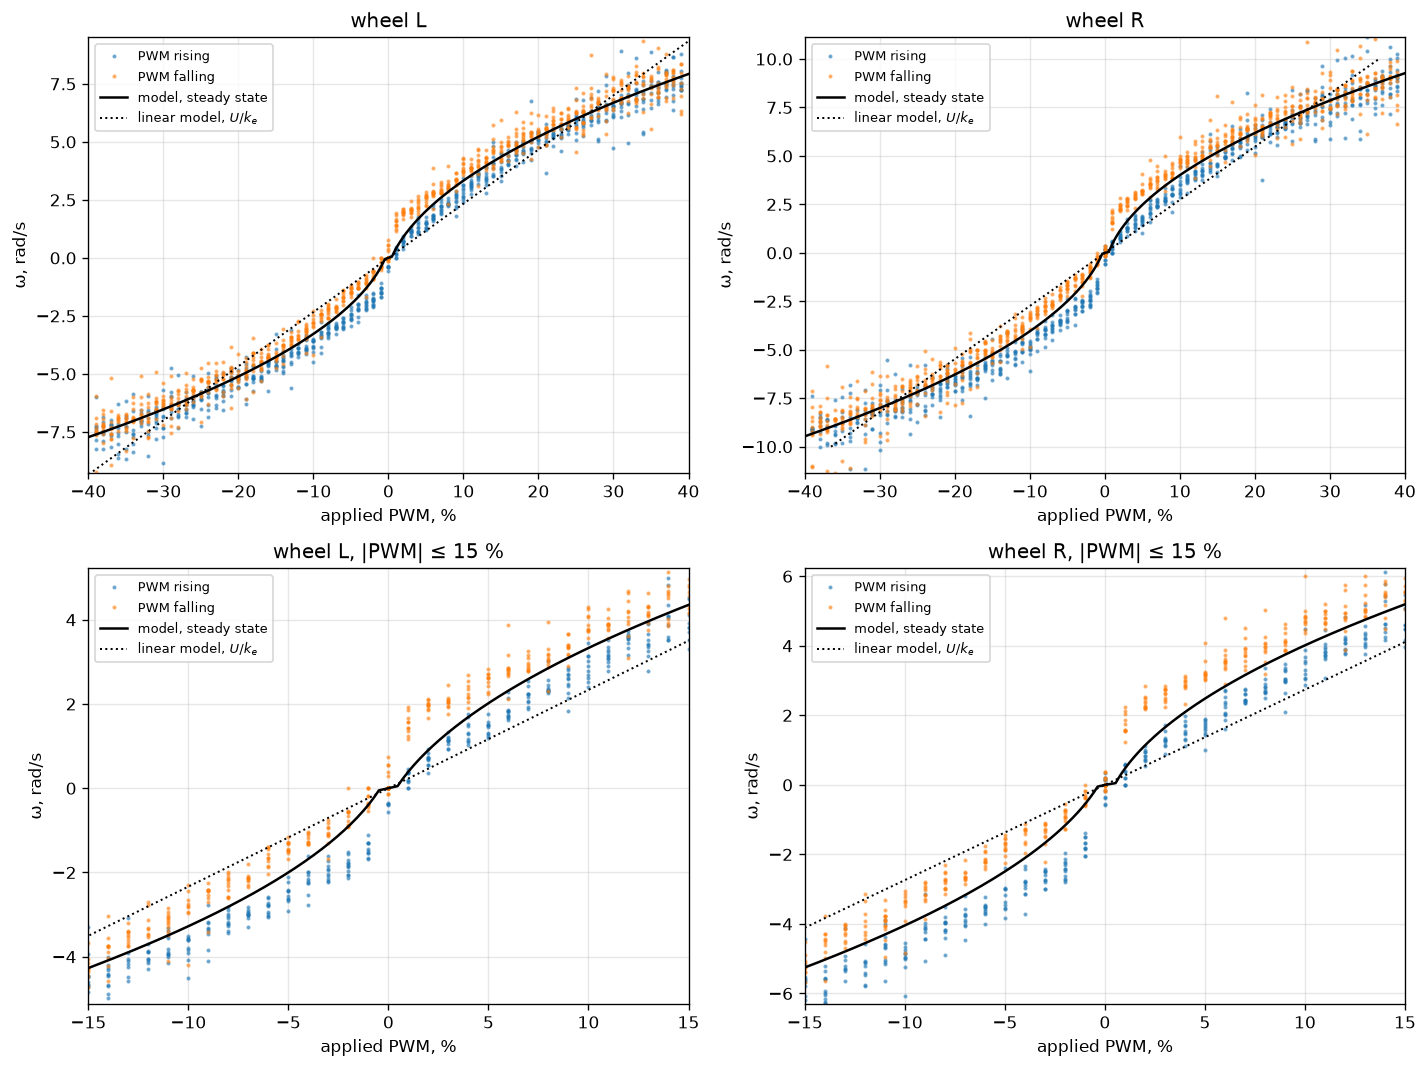

In [6]:
rising = (tri['t'][:-1] / 32) % 1 < 0.5                              # first half of each 32 s period: PWM rising
w_grid = np.linspace(-10, 10, 401)
fig, axes = plt.subplots(2, 2, figsize=(12, 9), dpi=120)
for col, wh in enumerate(('L', 'R')):
    w_meas = speed(tri['t'], tri[wh])
    pwm_ss = np.array([100 * friction(w, *popt[wh][:6]) / tri['bat'] for w in w_grid])   # steady state: U = U_f(w)
    for ax, lim in ((axes[0, col], 40), (axes[1, col], 15)):
        ax.plot(tri['pwm'][:-1][late & rising], w_meas[late & rising], '.', ms=3, alpha=0.5, label='PWM rising')
        ax.plot(tri['pwm'][:-1][late & ~rising], w_meas[late & ~rising], '.', ms=3, alpha=0.5, label='PWM falling')
        ax.plot(pwm_ss, w_grid, 'k-', lw=1.5, label='model, steady state')
        ax.plot(w_grid * 100 * lin[wh][0] / tri['bat'], w_grid, 'k:', lw=1.2, label='linear model, $U/k_e$')
        ax.set_xlim(-lim, lim); ax.set_ylim(np.interp([-lim, lim], pwm_ss, w_grid) * 1.2)
        ax.set_xlabel('applied PWM, %'); ax.set_ylabel('ω, rad/s')
        ax.set_title(f'wheel {wh}' + (', |PWM| ≤ 15 %' if lim == 15 else ''))
        ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig('report_figs/triangle_speed_pwm.png')

## Asymmetry
The PWM the model needs to hold the same speed, forward vs reverse and left vs right.

In [7]:
rows = []
for w in (1, 3, 5, 7):
    row = {'speed, rad/s': w}
    for wh in ('L', 'R'):
        row[f'{wh} fwd, %'] = 100 * friction(w, *popt[wh][:6]) / tri['bat']
        row[f'{wh} rev, %'] = -100 * friction(-w, *popt[wh][:6]) / tri['bat']
    row['L/R fwd'] = row['L fwd, %'] / row['R fwd, %']
    rows.append(row)
display(pd.DataFrame(rows).set_index('speed, rad/s').round(2))

,"L fwd, %","L rev, %","R fwd, %","R rev, %",L/R fwd
"speed, rad/s",,,,,
1,2.21,2.21,1.77,1.70,1.24
3,8.59,8.78,6.51,6.46,1.32
5,18.65,19.30,14.11,13.88,1.32
7,32.39,33.77,24.60,23.95,1.32


## Chirp: simulation
The model identified on the triangle (unchanged) is simulated with the chirp's applied voltage. At about 84 ms per row there are fewer than 6 samples per period above ≈ 2 Hz (from $t \approx 11.6$ s), so the fit is given for the whole run and for that first part.

wheel L, model : fit   -0.1 % (whole run),   85.0 % (f < 2 Hz)
wheel L, linear: fit   11.1 % (whole run),   10.9 % (f < 2 Hz)
wheel R, model : fit   37.6 % (whole run),   78.8 % (f < 2 Hz)
wheel R, linear: fit -126.2 % (whole run),  -35.1 % (f < 2 Hz)


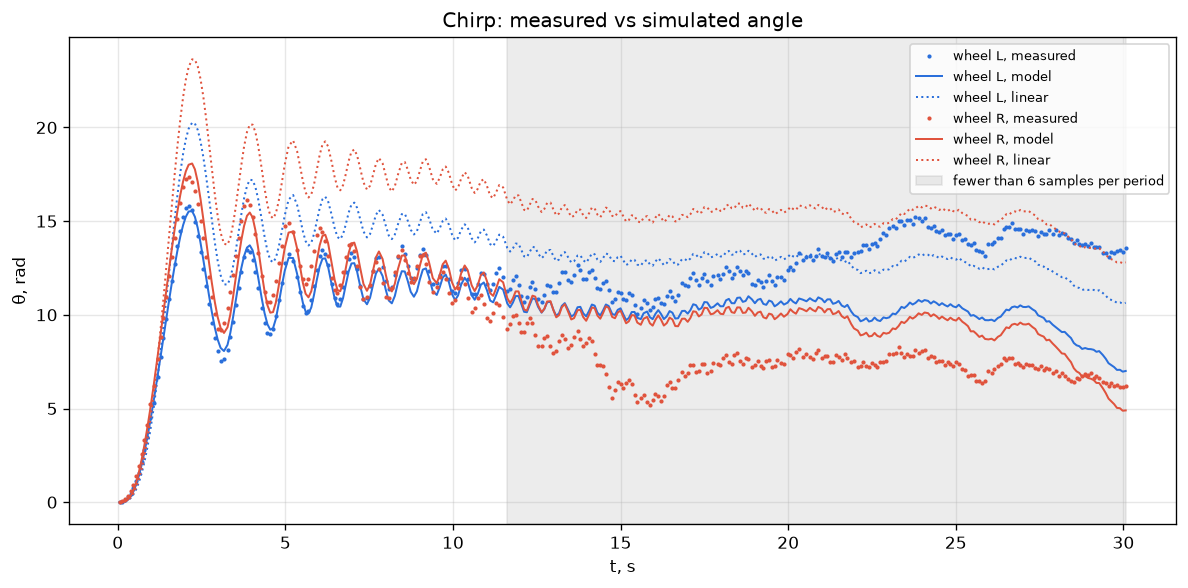

In [8]:
f0, f1, T_chirp = 0.1, 5, 30                                         # chirp settings in motor_signal_chirp.qrs
first = chp['t'] < 11.6                                              # f < 2 Hz
th_chp = {}
fig, ax = plt.subplots(figsize=(10, 5), dpi=120)
for wh in ('L', 'R'):
    th_chp[wh] = model(chp['t'], chp['U'], *popt[wh])
    th_lin = linear(chp['t'], chp['U'], *lin[wh])
    for name, th in (('model', th_chp[wh]), ('linear', th_lin)):
        print(f'wheel {wh}, {name:6s}: fit {fit_percent(chp[wh], th):6.1f} % (whole run), '
              f'{fit_percent(chp[wh][first], th[first]):6.1f} % (f < 2 Hz)')
    ax.plot(chp['t'], chp[wh], '.', color=colors[wh], ms=3, label=f'wheel {wh}, measured')
    ax.plot(chp['t'], th_chp[wh], '-', color=colors[wh], lw=1.2, label=f'wheel {wh}, model')
    ax.plot(chp['t'], th_lin, ':', color=colors[wh], lw=1.2, label=f'wheel {wh}, linear')
ax.axvspan(11.6, chp['t'][-1], color='grey', alpha=0.15, label='fewer than 6 samples per period')
ax.set_xlabel('t, s'); ax.set_ylabel('θ, rad'); ax.set_title('Chirp: measured vs simulated angle')
ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig('report_figs/chirp_sim.png')

## Chirp: amplitude ratio vs frequency
As in Assignment 1: speed amplitude over voltage amplitude in a window of one period, at the instantaneous frequency $f(t) = f_0 + (f_1 - f_0)\,t/T$. The same ratio is computed from the simulated angle, so measurement and model are compared in the same way.

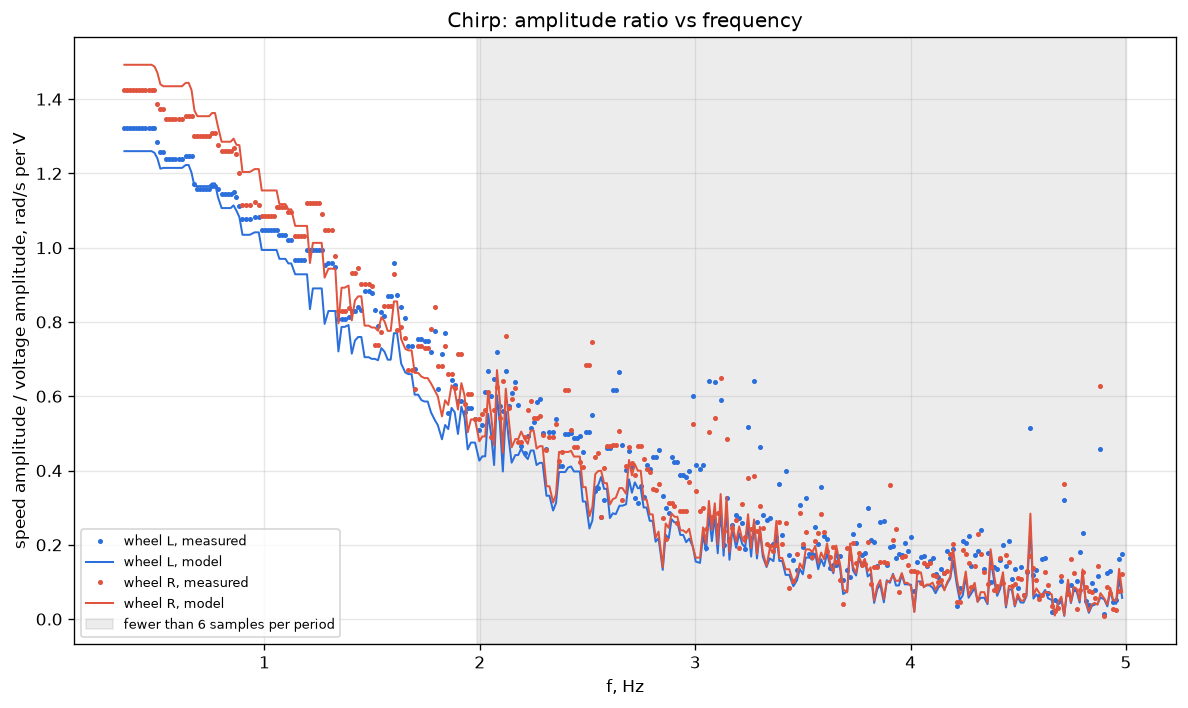

In [9]:
t_c, U_c = chp['t'], chp['U']
f_c = f0 + (f1 - f0) * t_c / T_chirp                                 # instantaneous frequency, Hz

def amplitude_ratio(theta):
    w = np.gradient(theta, t_c)                                      # speed, rad/s
    ratio = np.full(len(t_c), np.nan)
    for k in range(len(t_c)):
        half = 0.5 / f_c[k]                                          # half a period at this frequency, s
        if t_c[k] - half >= t_c[0] and t_c[k] + half <= t_c[-1]:     # a full period fits in the record
            win = np.abs(t_c - t_c[k]) <= half
            ratio[k] = np.ptp(w[win]) / np.ptp(U_c[win])             # speed amplitude / voltage amplitude
    return ratio

plt.figure(figsize=(10, 6), dpi=120)
for wh in ('L', 'R'):
    plt.plot(f_c, amplitude_ratio(chp[wh]), '.', color=colors[wh], ms=4, label=f'wheel {wh}, measured')
    plt.plot(f_c, amplitude_ratio(th_chp[wh]), '-', color=colors[wh], lw=1.2, label=f'wheel {wh}, model')
plt.axvspan(1 / np.median(np.diff(t_c)) / 6, f1, color='grey', alpha=0.15, label='fewer than 6 samples per period')
plt.xlabel('f, Hz'); plt.ylabel('speed amplitude / voltage amplitude, rad/s per V')
plt.title('Chirp: amplitude ratio vs frequency')
plt.grid(alpha=0.3); plt.legend(fontsize=8)
plt.tight_layout(); plt.savefig('report_figs/chirp_ratio.png')

## PRBS: validation
The PRBS (±20 %, clock 0.5 s, 127 s) was not used for fitting. It was run twice: on 12 Nov, the same afternoon as the triangle (its battery column is 0, so the triangle's voltage is used), and on 13 Nov with the battery logged. The 12 Nov run tests the model alone; the 13 Nov run also contains the change of the motors from one day to the next. The plot shows the 13 Nov run. Both models, identified on the triangle, are simulated with its applied voltage. The PRBS swings between +20 and −20 % and its angle stays near zero, so the fit % on the angle is sensitive to small drifts; the fit % on the speed is given as well.

12 Nov, wheel L, model : speed fit  71.1 %, angle fit  76.9 %
12 Nov, wheel L, linear: speed fit  67.5 %, angle fit  54.4 %
12 Nov, wheel R, model : speed fit  60.4 %, angle fit  85.5 %
12 Nov, wheel R, linear: speed fit  62.0 %, angle fit  73.7 %


13 Nov, wheel L, model : speed fit  68.3 %, angle fit  69.6 %
13 Nov, wheel L, linear: speed fit  67.0 %, angle fit  52.2 %
13 Nov, wheel R, model : speed fit  58.9 %, angle fit  62.6 %
13 Nov, wheel R, linear: speed fit  62.5 %, angle fit  84.8 %
wheel L: mean |ω| at ±20 % PWM 3.60 (12 Nov) → 3.41 rad/s (13 Nov), -5.2 %; battery -2.3 %
wheel R: mean |ω| at ±20 % PWM 4.04 (12 Nov) → 3.82 rad/s (13 Nov), -5.3 %; battery -2.3 %


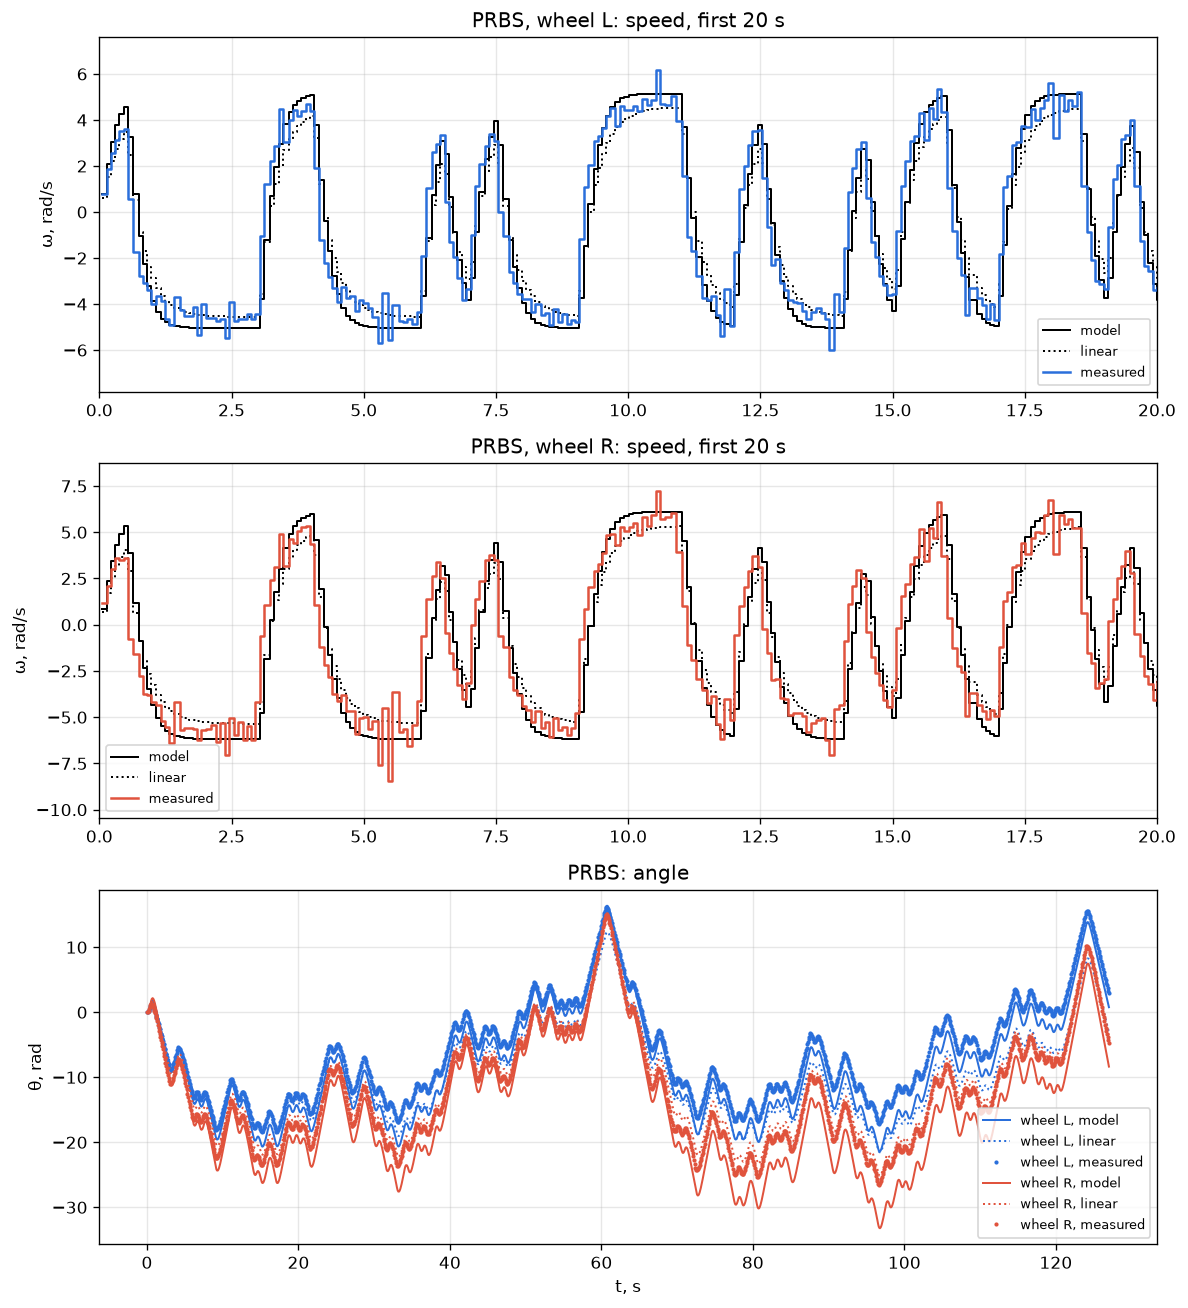

In [10]:
for day, s in (('12 Nov', prb_12), ('13 Nov', prb)):
    for wh in ('L', 'R'):
        for name, th in (('model', model(s['t'], s['U'], *popt[wh])), ('linear', linear(s['t'], s['U'], *lin[wh]))):
            print(f"{day}, wheel {wh}, {name:6s}: speed fit {fit_percent(speed(s['t'], s[wh]), speed(s['t'], th)):5.1f} %, angle fit {fit_percent(s[wh], th):5.1f} %")

for wh in ('L', 'R'):                                                # the same sequence on both days: how much slower on 13 Nov
    at20 = [np.abs(speed(s['t'], s[wh]))[np.abs(s['pwm'][:-1]) == 20].mean() for s in (prb_12, prb)]
    print(f"wheel {wh}: mean |ω| at ±20 % PWM {at20[0]:.2f} (12 Nov) → {at20[1]:.2f} rad/s (13 Nov), {100 * (at20[1] / at20[0] - 1):+.1f} %; "
          f"battery {100 * (prb['bat'] / prb_12['bat'] - 1):+.1f} %")

fig, axes = plt.subplots(3, 1, figsize=(10, 11), dpi=120)
for ax, wh in zip(axes, ('L', 'R')):
    w_meas = speed(prb['t'], prb[wh])
    for name, th, ls in (('model', model(prb['t'], prb['U'], *popt[wh]), '-'),
                         ('linear', linear(prb['t'], prb['U'], *lin[wh]), ':')):
        ax.step(prb['t'][:-1], speed(prb['t'], th), ls, where='post', color='k', lw=1.2, label=name)
        axes[2].plot(prb['t'], th, ls, color=colors[wh], lw=1.2, label=f'wheel {wh}, {name}')
    ax.step(prb['t'][:-1], w_meas, '-', where='post', color=colors[wh], lw=1.5, label='measured')
    ax.set_xlim(0, 20); ax.set_title(f'PRBS, wheel {wh}: speed, first 20 s'); ax.set_ylabel('ω, rad/s')
    axes[2].plot(prb['t'], prb[wh], '.', color=colors[wh], ms=3, label=f'wheel {wh}, measured')
axes[2].set_title('PRBS: angle'); axes[2].set_ylabel('θ, rad'); axes[2].set_xlabel('t, s')
for ax in axes:
    ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig('report_figs/prbs_validation.png')

## PRBS: timing
Each row's time is read at the start of the program's loop, but the encoders only after both motor commands, so a logged angle may be newer than its time stamp. To check, the simulated angle is moved earlier by 0–160 ms (one logging interval is ≈ 85–100 ms) and the speed fit is computed again. The triangle is the reference: it changes slowly, so its best shift should be near zero. Part of the best shift on the PRBS may also come from $\tau$, since a slower simulated response looks like a delay; the two cannot be separated here.

In [11]:
shifts = np.arange(0, 161, 10)                                       # ms: the simulation moved earlier by this much
rows = []
for name, s in (('triangle', tri), ('PRBS 12 Nov', prb_12), ('PRBS 13 Nov', prb)):
    for wh in ('L', 'R'):
        w_meas = speed(s['t'], s[wh])
        row = {'data': name, 'wheel': wh}
        for mname, th in (('model', model(s['t'], s['U'], *popt[wh])), ('linear', linear(s['t'], s['U'], *lin[wh]))):
            fits = [fit_percent(w_meas, speed(s['t'], np.interp(s['t'] + d / 1000, s['t'], th))) for d in shifts]
            best = int(np.argmax(fits))
            row[f'{mname}: as logged, %'] = fits[0]
            row[f'{mname}: best shift, ms'] = shifts[best]
            row[f'{mname}: shifted, %'] = fits[best]
        rows.append(row)
display(pd.DataFrame(rows).set_index(['data', 'wheel']).round(1))   # speed fit %

model: as logged, %  model: best shift, ms  \
data        wheel                                               
triangle    L                     90.5                      0   
            R                     89.1                     10   
PRBS 12 Nov L                     71.1                     80   
            R                     60.4                    120   
PRBS 13 Nov L                     68.3                     80   
            R                     58.9                    110   

                   model: shifted, %  linear: as logged, %  \
data        wheel                                            
triangle    L                   90.5                  83.1   
            R                   89.1                  81.5   
PRBS 12 Nov L                   84.4                  67.5   
            R                   83.9                  62.0   
PRBS 13 Nov L                   81.5                  67.0   
            R                   79.2                  62.5   

                   linear: best shift, ms  linear: shifted, %  
data        wheel                                              
triangle    L                          20                83.1  
            R                          10                81.5  
PRBS 12 Nov L                          90                77.5  
            R                         110                80.2  
PRBS 13 Nov L                          90                78.1  
            R                         110                79.3

## Artifacts
Logging interval of each signal against the 5 ms timer, and the zero block (3 s with the motors off before each signal).

triangle: Δt median 95 ms, max 188 ms; encoders after the zero block: 0, 0 deg
chirp   : Δt median 84 ms, max 135 ms; encoders after the zero block: 0, 0 deg
prbs    : Δt median 83 ms, max 150 ms; encoders after the zero block: 0, 0 deg


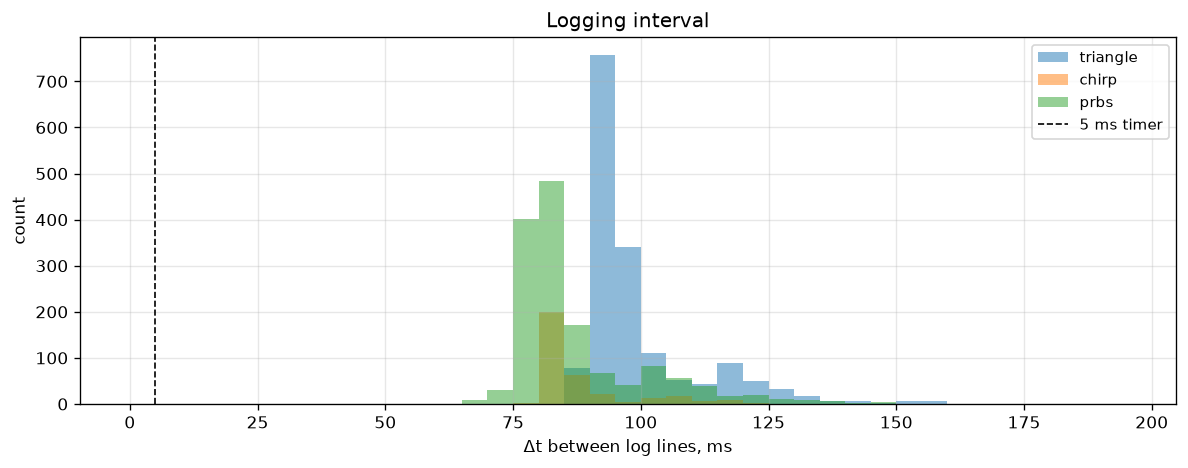

In [12]:
plt.figure(figsize=(10, 4), dpi=120)
for name, f in (('triangle', 'triangle_signal_data.txt'), ('chirp', 'chirp_signal_data.txt'), ('prbs', 'prbs_signal_data_2.txt')):
    data = np.loadtxt(os.path.join(DATA, f))
    zero = data[data[:, 0] == 2][0]                                  # the zero-block line, motors off
    dt_ms = np.diff(data[data[:, 0] == 3][:, 4])                     # time between log lines, ms
    print(f'{name:8s}: Δt median {np.median(dt_ms):.0f} ms, max {dt_ms.max():.0f} ms; '
          f'encoders after the zero block: {zero[2]:.0f}, {zero[3]:.0f} deg')
    plt.hist(dt_ms, bins=np.arange(0, 200, 5), alpha=0.5, label=name)
plt.axvline(5, color='k', ls='--', lw=1, label='5 ms timer')
plt.xlabel('Δt between log lines, ms'); plt.ylabel('count'); plt.title('Logging interval')
plt.grid(alpha=0.3); plt.legend(fontsize=9)
plt.tight_layout(); plt.savefig('report_figs/dt_jitter.png')

## Compensation
`pwm_for_speed` is the model solved for the voltage: $U = U_f(\omega_{ref}) + \tau\,\dot\omega_{ref}$, sent as PWM at the present battery voltage and clipped to ±100 %. All the non-linearities are in it through $U_f$. The term $\tau\,\dot\omega_{ref}$ is the voltage needed to accelerate; it matters while the desired speed changes, and the wheels need different amounts of it because their $\tau$ differ. The model is identified for $|\mathrm{PWM}| \le 40\,\%$ (the triangle's range); above that it is an extrapolation.

L {-6: -26.0, -2: -5.0, -0.5: -1.2, 0: 0.0, 0.5: 1.2, 2: 4.9, 6: 25.1}
R {-6: -18.6, -2: -3.7, -0.5: -0.9, 0: 0.0, 0.5: 1.0, 2: 3.8, 6: 19.0}


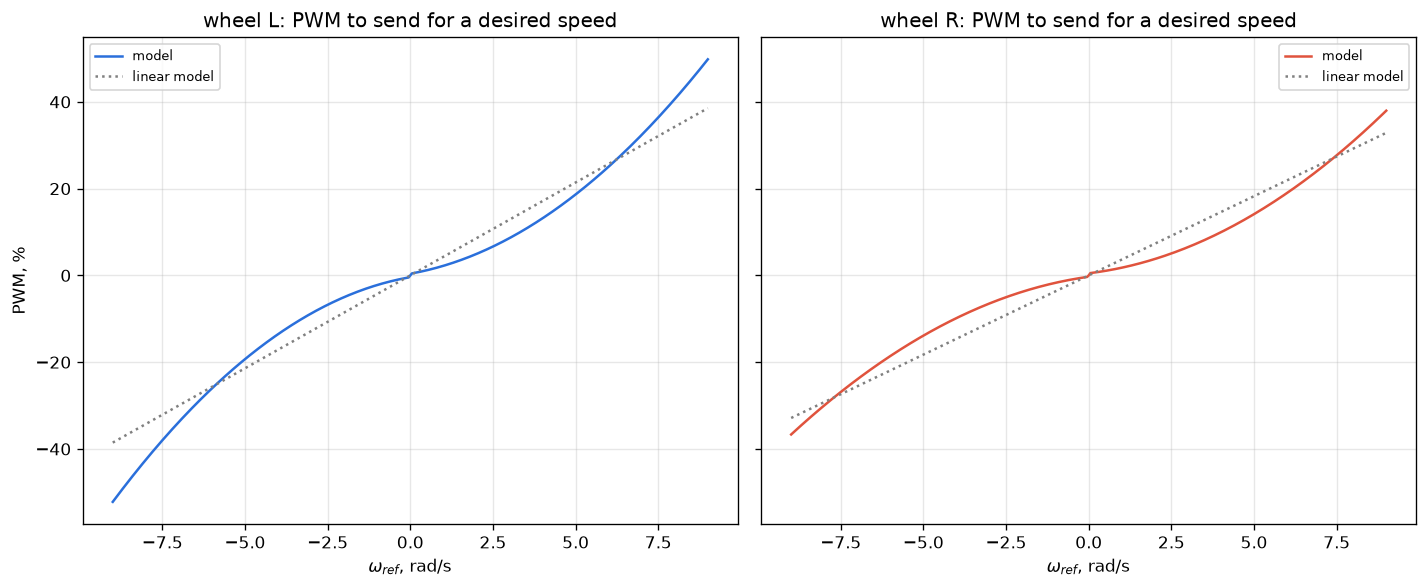

In [13]:
def pwm_for_speed(w_ref, wheel, u_bat, dw_ref=0):
    # PWM (%) to send for a desired wheel speed w_ref (rad/s) and its rate of change dw_ref (rad/s^2), at battery voltage u_bat (V)
    tau = popt[wheel][6]
    U = friction(w_ref, *popt[wheel][:6]) + tau * dw_ref             # the model solved for U
    return float(np.clip(100 * U / u_bat, -100, 100))                # as PWM, limited to ±100 % (saturation)

def pwm_linear(w_ref, wheel, u_bat):
    return float(np.clip(100 * lin[wheel][0] * w_ref / u_bat, -100, 100))   # the linear model inverted, for comparison

w_grid = np.linspace(-9, 9, 361)
fig, axes = plt.subplots(1, 2, figsize=(12, 5), dpi=120, sharey=True)
for ax, wh in zip(axes, ('L', 'R')):
    ax.plot(w_grid, [pwm_for_speed(w, wh, tri['bat']) for w in w_grid], '-', color=colors[wh], label='model')
    ax.plot(w_grid, [pwm_linear(w, wh, tri['bat']) for w in w_grid], ':', color='grey', label='linear model')
    ax.set_xlabel('$\\omega_{ref}$, rad/s'); ax.set_title(f'wheel {wh}: PWM to send for a desired speed')
    ax.grid(alpha=0.3); ax.legend(fontsize=8)
axes[0].set_ylabel('PWM, %')
plt.tight_layout(); plt.savefig('report_figs/compensation.png')

for wh in ('L', 'R'):
    print(wh, {w: round(pwm_for_speed(w, wh, tri['bat']), 1) for w in (-6, -2, -0.5, 0, 0.5, 2, 6)})

**The same function in a TRIK Function block**, for the test program. TRIK has no `if` inside an expression, so the direction is selected with `abs`, and the clip is written as $(|u + 100| - |u - 100|)/2$. `w` is the desired speed in rad/s, `dw` its rate of change in rad/s² (in the loop: `dw = (w - w_old)/(ts - ts_old)`), and `Ubat` the battery voltage in V.

In [14]:
lines = ['wa = abs(w)', 'wp = (w + wa)/2', 'wn = (wa - w)/2']
for wh in ('L', 'R'):
    U0f, af, cf, U0r, ar, cr, tau = popt[wh]
    lines += [f'U{wh} = wp/(wa + 0.000001)*({U0f:.5f} + {af:.5f}*wp + {cf:.5f}*wp*wp)'
              f' - wn/(wa + 0.000001)*({U0r:.5f} + {ar:.5f}*wn + {cr:.5f}*wn*wn) + {tau:.5f}*dw',
              f'u{wh} = 100*U{wh}/Ubat',
              f'u{wh} = (abs(u{wh} + 100) - abs(u{wh} - 100))/2']
print('\n'.join(lines))

wa = abs(w)
wp = (w + wa)/2
wn = (wa - w)/2
UL = wp/(wa + 0.000001)*(0.04337 + 0.15028*wp + 0.05096*wp*wp) - wn/(wa + 0.000001)*(0.04569 + 0.14518*wn + 0.05478*wn*wn) + 0.11291*dw
uL = 100*UL/Ubat
uL = (abs(uL + 100) - abs(uL - 100))/2
UR = wp/(wa + 0.000001)*(0.05394 + 0.10290*wp + 0.03988*wp*wp) - wn/(wa + 0.000001)*(0.03445 + 0.11719*wn + 0.03676*wn*wn) + 0.10261*dw
uR = 100*UR/Ubat
uR = (abs(uR + 100) - abs(uR - 100))/2


## Test on the robot
The model is tested on the robot as a feedforward speed controller. The desired speed follows a slow triangle, $\omega_{ref} = W(1 - 4|\mathrm{frac}(t/P) - 0.5|)$ with $W$ = 6 rad/s and $P$ = 32 s, for two periods with the model (phase 4) and two periods with the linear model (phase 5), in one run (`motor_model_test.qrs`). The run was done twice (`model_test_data.txt`, `model_test_data_2.txt`); the plot shows run 1, the tables show both. The linear model also gets its acceleration term, $k_e(\omega_{ref} + T_m\dot\omega_{ref})$, so the comparison is fair. The first 1.5 s are left out: the triangle starts at $-W$. Each wheel gets its own PWM from `pwm_for_speed`, including the $\tau\,\dot\omega_{ref}$ term. Both wheels get the same $\omega_{ref}$, so $\omega_L/\omega_R$ is the asymmetry that is left: a robot on the floor driving forward would turn at $r(\omega_R - \omega_L)/W$. The last row of the second table is the same PWM to both wheels, from the 13 Nov PRBS, as the uncompensated reference. Log columns: phase, $\omega_{ref}$ (rad/s), PWM L, PWM R (%), encoder L, encoder R (deg), time (ms), battery (V), in `model_test_data*.txt`.

RMSE, rad/s  RMSE for |ω_ref| < 2  \
run controller wheel                                      
1   model      L             0.49                  0.35   
               R             0.57                  0.31   
    linear     L             0.62                  0.65   
               R             0.83                  0.65   
2   model      L             0.49                  0.37   
               R             0.55                  0.39   
    linear     L             0.74                  0.67   
               R             0.94                  0.77   

                      speed error for |ω_ref| > 2, %  
run controller wheel                                  
1   model      L                               -8.21  
               R                              -11.63  
    linear     L                                8.27  
               R                               17.17  
2   model      L                               -5.17  
               R                               -6.84  
    linear     L                               12.06  
               R                               18.08

battery, V  ω_L/ω_R for |ω_ref| > 2  \
run  controller                                             
1    model                 10.94                     1.04   
     linear                10.91                     0.92   
2    model                 10.79                     1.02   
     linear                10.77                     0.95   
PRBS none (same PWM)       10.83                     0.89   

                      RMS ω_L − ω_R, rad/s  yaw driving forward, deg/s  
run  controller                                                         
1    model                            0.38                       -2.16  
     linear                           0.48                        2.82  
2    model                            0.31                       -0.49  
     linear                           0.42                        2.09  
PRBS none (same PWM)                  0.76                        6.05

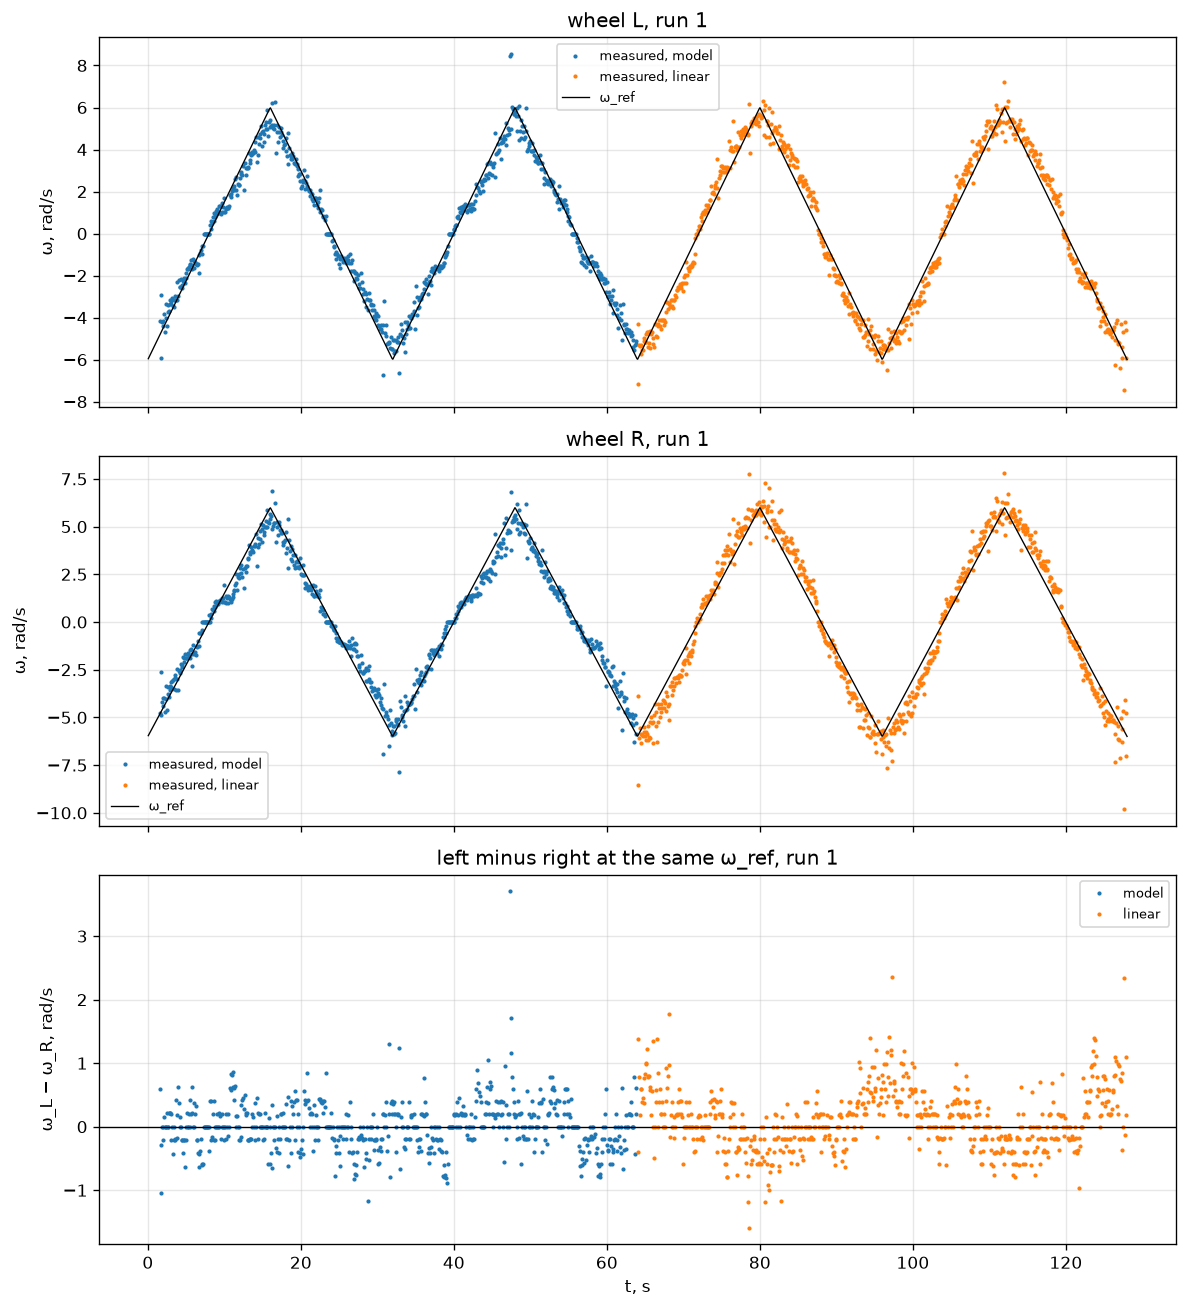

In [15]:
tests = [f for f in ('model_test_data.txt', 'model_test_data_2.txt') if os.path.exists(os.path.join(DATA, f))]
r_wheel, W = 0.043, 0.194                                            # wheel radius and track width, m (as in Assignment 1)
yaw = lambda w_L, w_R, fwd: np.degrees(r_wheel * np.mean(w_R[fwd] - w_L[fwd]) / W)   # deg/s, driving forward
fig, axes = plt.subplots(3, 1, figsize=(10, 11), dpi=120, sharex=True)
rows, asym = [], []
for run, f in enumerate(tests, 1):
    test = np.loadtxt(os.path.join(DATA, f))                         # columns: phase, w_ref, PWM L, PWM R, encL, encR, time_ms, battery
    for phase, name in ((4, 'model'), (5, 'linear')):
        d = test[test[:, 0] == phase]
        if phase == 4:
            d = d[d[:, 6] > 1500]                                    # leave out the opening jump to -W
        t, w_ref = d[:, 6] / 1000, d[:-1, 1]                         # w_ref during each logging interval
        w = {'L': speed(t, np.deg2rad(d[:, 4])), 'R': speed(t, np.deg2rad(d[:, 5]))}   # measured speeds, rad/s
        slow, fast = np.abs(w_ref) < 2, np.abs(w_ref) > 2
        for wh in ('L', 'R'):
            error = w[wh] - w_ref                                    # tracking error, rad/s
            rows.append({'run': run, 'controller': name, 'wheel': wh,
                         'RMSE, rad/s': np.sqrt(np.mean(error**2)),
                         'RMSE for |ω_ref| < 2': np.sqrt(np.mean(error[slow]**2)),
                         'speed error for |ω_ref| > 2, %': 100 * (np.abs(w[wh][fast]).sum() / np.abs(w_ref[fast]).sum() - 1)})
        asym.append({'run': run, 'controller': name, 'battery, V': np.median(d[:, 7]),
                     'ω_L/ω_R for |ω_ref| > 2': np.abs(w['L'][fast]).sum() / np.abs(w['R'][fast]).sum(),
                     'RMS ω_L − ω_R, rad/s': np.sqrt(np.mean((w['L'] - w['R'])**2)),
                     'yaw driving forward, deg/s': yaw(w['L'], w['R'], w_ref > 2)})
        if run == 1:
            for ax, wh in zip(axes, ('L', 'R')):
                ax.plot(t[:-1], w[wh], '.', ms=3, label=f'measured, {name}')
            axes[2].plot(t[:-1], w['L'] - w['R'], '.', ms=3, label=name)
    if run == 1:
        for ax, wh in zip(axes, ('L', 'R')):
            ax.plot(test[test[:, 0] >= 4][:, 6] / 1000, test[test[:, 0] >= 4][:, 1], 'k-', lw=0.8, label='ω_ref')
            ax.set_title(f'wheel {wh}, run 1'); ax.set_ylabel('ω, rad/s'); ax.grid(alpha=0.3); ax.legend(fontsize=8)

w_L, w_R = speed(prb['t'], prb['L']), speed(prb['t'], prb['R'])     # the PRBS: the same PWM to both wheels
asym.append({'run': 'PRBS', 'controller': 'none (same PWM)', 'battery, V': prb['bat'],
             'ω_L/ω_R for |ω_ref| > 2': np.abs(w_L).sum() / np.abs(w_R).sum(),
             'RMS ω_L − ω_R, rad/s': np.sqrt(np.mean((w_L - w_R)**2)),
             'yaw driving forward, deg/s': yaw(w_L, w_R, prb['pwm'][:-1] > 0)})
axes[2].axhline(0, color='k', lw=0.8)
axes[2].set_title('left minus right at the same ω_ref, run 1'); axes[2].set_ylabel('ω_L − ω_R, rad/s'); axes[2].set_xlabel('t, s')
axes[2].grid(alpha=0.3); axes[2].legend(fontsize=8)
plt.tight_layout(); plt.savefig('report_figs/robot_test.png')
display(pd.DataFrame(rows).set_index(['run', 'controller', 'wheel']).round(2))
display(pd.DataFrame(asym).set_index(['run', 'controller']).round(2))

## Model performance: summary
The results of the sections above in one place. Fit % as above: 100 % is a perfect match, 0 % is no better than the mean.

**Simulation.** Both models get the measured voltage, and their output is compared with the encoders.

| Data | New to the model? | Model, L / R | Linear model, L / R |
|---|---|---|---|
| Triangle, angle fit | no, fitted on it | 98.2 / 97.8 % | 84.2 / 82.9 % |
| Chirp below 2 Hz (PWM up to ±80 %), angle fit | yes | 85.0 / 78.8 % | 10.9 / -35.1 % |
| Chirp, whole run (up to 5 Hz), angle fit | yes | -0.1 / 37.6 % | 11.1 / -126.2 % |
| PRBS 12 Nov, speed fit | yes | 71.1 / 60.4 % | 67.5 / 62.0 % |
| PRBS 13 Nov, speed fit | yes, and the next day | 68.3 / 58.9 % | 67.0 / 62.5 % |
| PRBS 12 Nov, speed fit, simulation moved 80-120 ms earlier | yes | 84.4 / 83.9 % | 77.5 / 80.2 % |
| PRBS 13 Nov, speed fit, simulation moved 80-120 ms earlier | yes, and the next day | 81.5 / 79.2 % | 78.1 / 79.3 % |

**Compensation on the robot.** 13 Nov, runs 1 / 2, wheels lifted, the same $\omega_{ref}$ for both wheels.

| | Model | Linear model | Same PWM to both (13 Nov PRBS) |
|---|---|---|---|
| $\omega_L/\omega_R$ above 2 rad/s | 1.04 / 1.02 | 0.92 / 0.95 | 0.89 |
| Turning rate driving forward, °/s | -2.2 / -0.5 | 2.8 / 2.1 | 6.1 |
| Speed RMSE below 2 rad/s, rad/s | 0.31-0.39 | 0.65-0.77 | — |
| Speed error above 2 rad/s | -5 to -12 % | +8 to +18 % | — |

**Strengths.** The model captures the static non-linearities: the small dead zone, the curved relation between speed and voltage, and the asymmetry between the wheels and between the directions. Used for compensation, it removes almost all of the left/right asymmetry and halves the speed error at low speeds. One straight line, the linear model, cannot do either.

**Weaknesses.**
1. Fast changes. On the PRBS, which is mostly switching, both models fit the speed only 60-70 % as logged, and on the right wheel the linear model scores slightly higher. Most of this is timing (PRBS: timing): with the simulation moved about one logging interval earlier, both fit 78-84 %, and the model fits better than the linear model in 3 of 4 cases and ties in the fourth. Part of that shift may come from $\tau$ instead, so the transients are the least certain part of the model. The chirp above 2 Hz cannot judge them, as the logging (≈ 84 ms) is too coarse; its whole-run fit and the PRBS angle fit are not used to compare the models.
2. Another day. On 13 Nov the wheels turned ≈ 5 % slower at ±20 % PWM than on 12 Nov (PRBS section), and the battery explains ≈ 2 % of that. The parameters are from 12 Nov, so the compensated wheels ran 5-12 % slow. A feedforward model cannot correct this; feedback from the encoders could.
3. Range. The model is identified for |PWM| ≤ 40 % (the triangle). The chirp checks it up to ±80 % at low frequencies; above 80 % it is not tested.

## Analysis

### 1. Dead zone
It is much smaller than 5%. The start/stop table shows both wheels starting at 0-2% PWM and stopping at 0-1%, and the fitted $U_0$ is only 0.3-0.5% PWM, less than one PWM step. So the first whole PWM value already moves the wheel. The step series could not show this, since its smallest level was 10% and the wheels moved at every level. The chirp narrowed it to 2-7%, but near zero it changes too fast for the 84 ms logging; the triangle is 10 times slower, so it resolves 1%. Therefore, $\delta = 4\%$ from the previous findings was too large, and the new model does not need it, since the dead zone is the $U_0$ term.

### 2. Steady-state curve and Coulomb friction
The speed vs PWM curve is steep near zero and flattens at higher PWM, so a straight line can only fit one part of it. The Assignment 1 line fitted the high part and missed the low one, and the linear model fitted on the triangle misses both ends (84 / 83% fit vs 98 / 98% for the model). The $c\,\omega^2$ term describes this bending.

$U_0$ and the coasting deceleration both show that Coulomb friction exists, but they disagree on its size: the coast predicted a dead zone of 17-25% PWM, while the wheels start at 1-2%. A possible reason (a hypothesis) is that they are measured in different states: $U_0$ with the motor powered, $a_c$ after `powerOff()`. It was not tested. For the compensation $U_0$ is the right one, since the robot drives with the motors powered.

### 3. Asymmetry
Forward vs reverse differs by at most ≈ 4% (relative), so it is small. Left vs right is the big one: the left wheel needs 24-32% more PWM than the right one for the same speed. With the same PWM on both wheels, the robot turns towards the slower, left side, about 6 deg/s at 20% PWM, so it cannot drive straight without compensation.

### 4. Dynamics: what the chirp and the PRBS showed
According to $T = \tau/(a + 2c|\omega|)$, the time constant gets shorter as the speed grows (≈ 0.5 s at 1 rad/s, ≈ 0.15 s at 7 rad/s). That explains why $T_m$ changed with PWM in Assignment 1: it was not noise but the non-linearity.

On the chirp below 2 Hz, the model fits 85 / 79% while the linear model fits 11 / -35%, even though the chirp goes up to 80% PWM. On the PRBS both models fit the speed about the same as logged (60-70%), so at first the model does not seem to describe fast changes better. Part of this is probably the logging: each row's time is read at the start of the loop, but the encoders only after the motor commands, so the logged angles are newer than their time stamps, and the simulation runs behind the data by up to about one interval. Moving the simulation 80-120 ms earlier raises the PRBS speed fits to 78-84%, and then the model fits better than the linear one in 3 of 4 cases (PRBS: timing). Above 2 Hz the chirp cannot judge the model, since there are fewer than 6 samples per period. The model also fits worse on the next day (13 Nov), when the wheels were ≈ 5% slower.

### 5. The model and the compensation
The voltage splits into two parts: $\tau\,\dot\omega$ accelerates the wheel, and $U_f(\omega)$ is taken up by back-EMF and friction. $U_0$ handles Coulomb friction and the dead zone, $a|\omega|$ back-EMF and viscous friction, and $c\,\omega^2$ the bending of the curve. Separate parameters per wheel and direction handle the asymmetry, and the clip to ±100% handles saturation. The compensation is the same equation solved for $U$. The model is valid for lifted wheels, $|\mathrm{PWM}| \le 40\%$ (checked up to 80% by the chirp), below ≈ 2 Hz, and on the day it was identified.

### 6. Test on the robot
With the model, the speed error at low speed is halved (RMSE 0.31-0.39 vs 0.65-0.77 rad/s). At higher speeds the model is 5-12% too slow, while the linear one is 8-18% too fast. The undershoot partly comes from the parameters being identified the day before, when the wheels were ≈ 5% faster. The left/right ratio goes from 0.89 (same PWM) to 1.02-1.04, so most of the asymmetry is removed, and the robot turns at 0.5-2 deg/s instead of 6 deg/s. To remove the rest, I would add feedback from the encoders on top of the model, and identify the parameters on the floor, since all of this was done with the wheels unloaded.
